# Analyzing a force spectroscopy map

This notebook opens a Nanosurf force map and fits every curve with the DMT contact mechanics model, to make maps of the
Young's modulus and the adhesion. Run it from this folder, next to `spectroscopy.nid`.

The tip radius and Poisson ratio below are assumptions: the modulus scales with them, so set them for your own sample.

In [1]:
from NSFopen.process import process

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

from glob import glob
from pathlib import Path

RADIUS = 10e-9  # tip radius in m
NU = 0.35  # Poisson ratio, between 0.35 and 0.5

filename = "spectroscopy.nid"

Set `USE_LARGE_MAP` to True to analyze a larger map, which is downloaded the first time.

In [2]:
USE_LARGE_MAP = False

if USE_LARGE_MAP:
    filename = "spectroscopy_large.nid"
    if not Path(filename).exists():
        import urllib.request

        urllib.request.urlretrieve("https://www.dropbox.com/s/knzuh588g0uvjfi/spectroscopy_large.nid?dl=1", filename)

## Read the file

The `Backward` modulation is the retract part of the curves, which holds the adhesion. The Z channel has a different name
on different systems.

In [3]:
afm = process(filename, verbose=False)
param = afm.param

k = param.Tip.Prop0["Value"]  # spring constant in N/m

curves = afm.data["Spec"]["Backward"]
force = curves["Deflection"]  # in N
z_channel = next(name for name in ("Z-Axis Sensor", "Z-AxisSensor", "Z-Axis") if name in curves.index)
z = curves[z_channel]  # in m

x_min, x_max, y_min, y_max, n_x, n_y = param.Spec.maps[:6]  # positions of the first and last points, number of points
n_x, n_y = int(n_x), int(n_y)
print(f"{len(force)} curves on a grid of {n_x} x {n_y}, k = {k:.2f} N/m")

100 curves on a grid of 10 x 10, k = 2.72 N/m


## The model

`tilt_removed` subtracts a line fitted to the part of the curve away from the surface. `dmt_fit` fits one curve from the
point of largest adhesion on; it returns NaN where the fit does not converge.

In [4]:
def tilt_removed(x, y, start=0.5, end=0.8):
    i0, i1 = int(len(x) * start), int(len(x) * end)
    return y - np.polyval(np.polyfit(x[i0:i1], y[i0:i1], 1), x)


def dmt(x, modulus, contact, adhesion):
    scale = 4 / 3 * modulus * np.sqrt(RADIUS) / (1 - NU**2)
    x = x - contact
    return scale * np.sign(x) * np.abs(x) ** 1.5 - adhesion


def dmt_fit(separation, load):
    start = int(len(load) * 0.8)
    pull_off = load[start:].min()
    i0 = np.flatnonzero(load == pull_off)[0]
    try:
        coefficients, _ = curve_fit(dmt, separation[i0:], load[i0:], p0=[1e9, separation[i0], -pull_off])
    except (RuntimeError, ValueError):
        return np.nan, None, i0
    return max(coefficients[0], 0.0), coefficients, i0

## Fit all curves

The separation of tip and sample is the Z position minus the bending of the cantilever.

In [5]:
loads = [tilt_removed(z_, f_) for z_, f_ in zip(z, force)]
separations = [z_ - f_ / k for z_, f_ in zip(z, loads)]

modulus = np.array([dmt_fit(s, f)[0] for s, f in zip(separations, loads)])
adhesion = np.array([-f.min() for f in loads])

print(f"Modulus: median {np.nanmedian(modulus) / 1e9:.2f} GPa, {np.isnan(modulus).sum()} of {modulus.size} fits failed")
print(f"Adhesion: median {np.median(adhesion) * 1e9:.1f} nN")

Modulus: median 4.09 GPa, 15 of 100 fits failed
Adhesion: median 9.4 nN


## Maps

The curves are in the order they were measured: every other line of the grid runs backward. `to_map` puts them in place.
Row 0 of a map is the first line scanned, like row 0 of the images, so `afm.origin` draws them the same way up. Gray
points of the modulus map are curves whose fit failed.

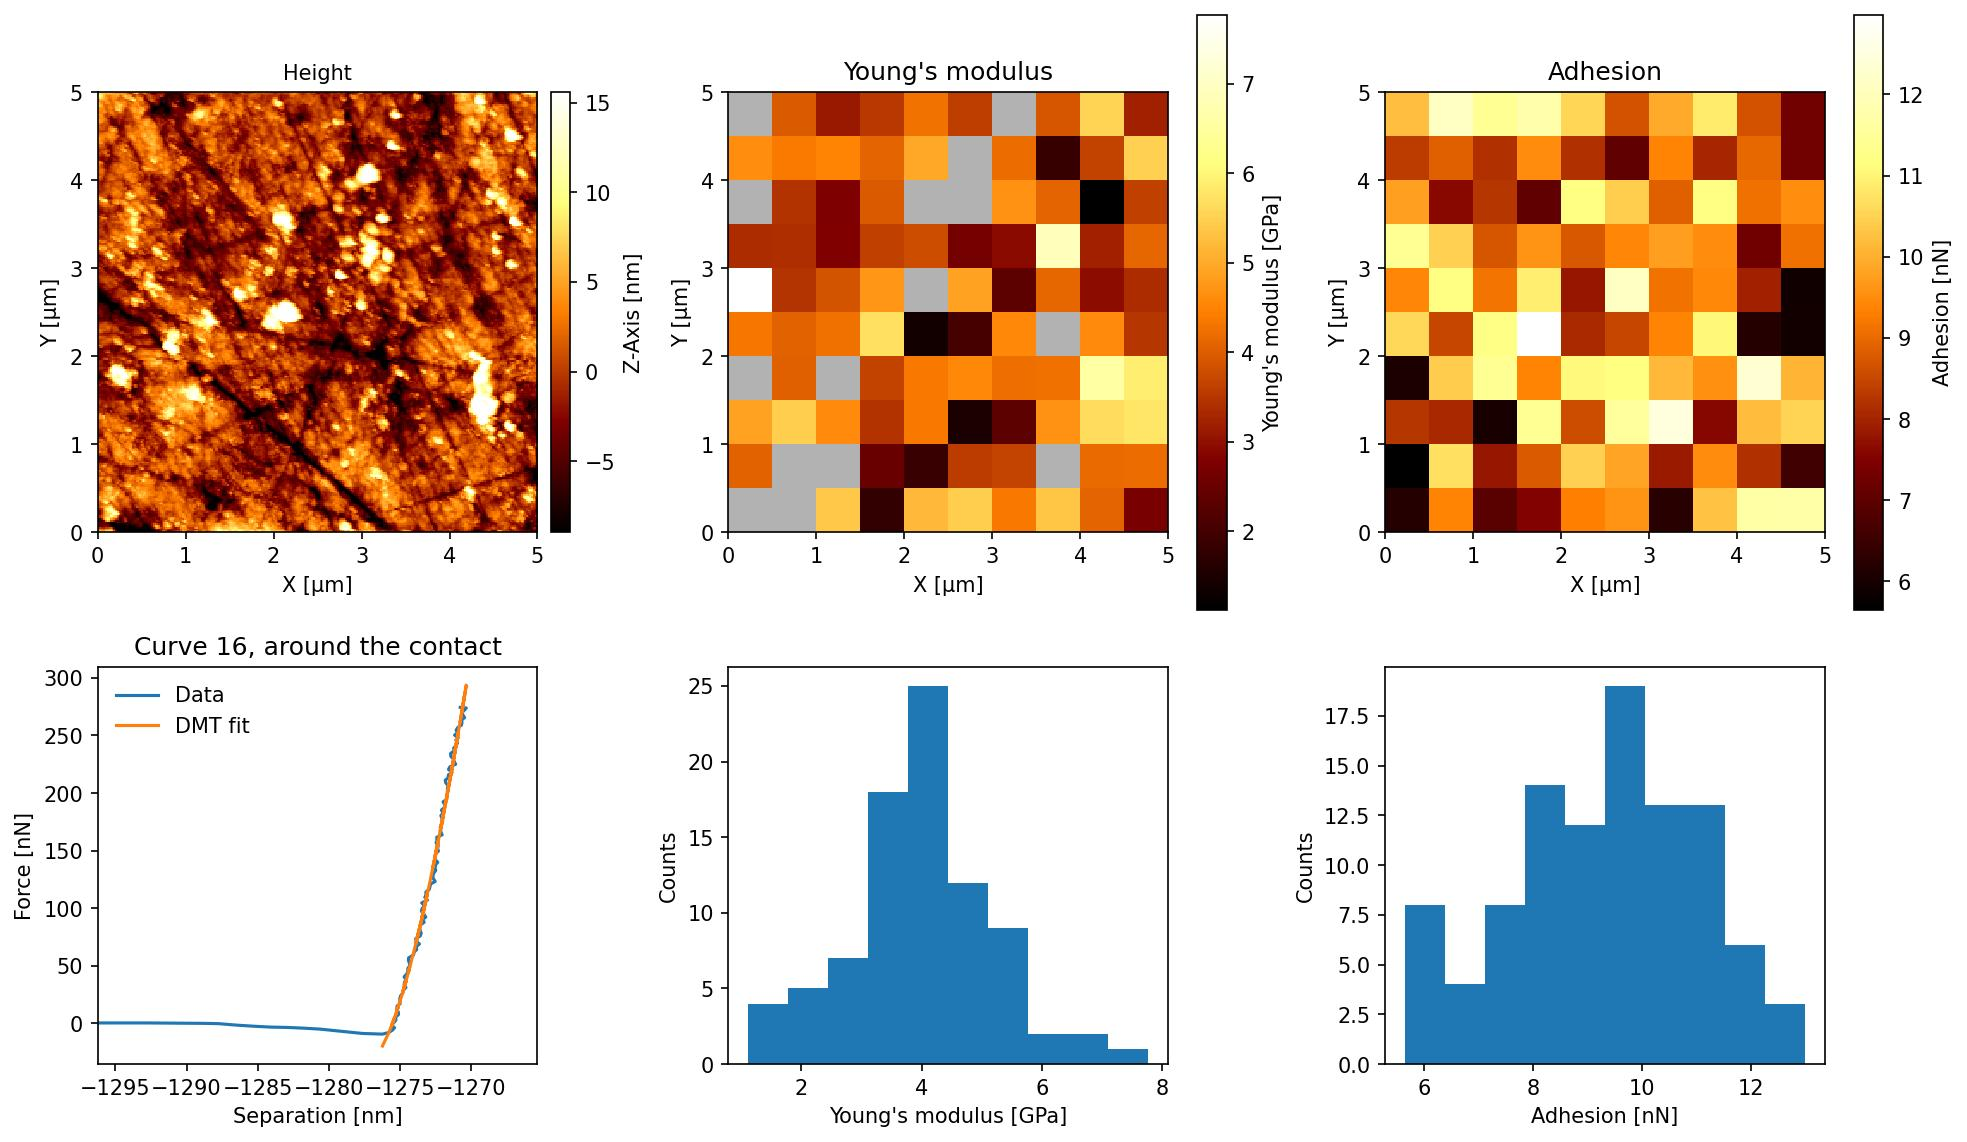

In [6]:
def to_map(values):
    grid = np.reshape(values, (n_y, n_x)).copy()
    grid[1::2] = grid[1::2, ::-1]
    return grid


half_x, half_y = (x_max - x_min) / (n_x - 1) / 2, (y_max - y_min) / (n_y - 1) / 2  # half a grid step at each side
extent = (0, (x_max - x_min + 2 * half_x) * 1e6, 0, (y_max - y_min + 2 * half_y) * 1e6)

colors = plt.get_cmap("afmhot").copy()
colors.set_bad("0.7")

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), layout="constrained", dpi=150, height_ratios=[3, 2])

afm.flatten()
afm.image(ax=axes[0, 0], color_range="p1", title="Height")

for ax, values, label in ((axes[0, 1], modulus / 1e9, "Young's modulus [GPa]"), (axes[0, 2], adhesion * 1e9, "Adhesion [nN]")):
    image = ax.imshow(to_map(values), extent=extent, origin=afm.origin, cmap=colors)
    ax.set(xlabel="X [µm]", ylabel="Y [µm]", title=label.split(" [")[0])
    fig.colorbar(image, ax=ax, label=label)

# one curve with its fit, here the one with the median modulus
index = int(np.nanargmin(np.abs(modulus - np.nanmedian(modulus))))
coefficients, i0 = dmt_fit(separations[index], loads[index])[1:]
s = separations[index]
axes[1, 0].plot(s * 1e9, loads[index] * 1e9, label="Data")
axes[1, 0].plot(s[i0:] * 1e9, dmt(s[i0:], *coefficients) * 1e9, label="DMT fit")
axes[1, 0].set(xlabel="Separation [nm]", ylabel="Force [nN]", title=f"Curve {index}, around the contact",
               xlim=((s[i0:].min() - 20e-9) * 1e9, (s[i0:].max() + 5e-9) * 1e9))
axes[1, 0].legend(frameon=False)

axes[1, 1].hist(modulus[np.isfinite(modulus)] / 1e9)
axes[1, 1].set(xlabel="Young's modulus [GPa]", ylabel="Counts")
axes[1, 2].hist(adhesion * 1e9)
axes[1, 2].set(xlabel="Adhesion [nN]", ylabel="Counts")
plt.show()